# Story 1: the baseline effect

Step 2 of the analysis plan ([`final-analysis-plan.md`](../../docs/analysis/final-analysis-plan.md) §4). **Question:** when a cell's lights grow faster than
those of similar cells in its country-biome-year, do its nights get cooler, and does that
survive the mundane explanations?

| Order | Notebook | Question |
|---|---|---|
| 1 | `01_pre_analysis.ipynb` | What do the stories rely on? No outcome-on-treatment regressions. |
| 2 | `02_baseline.ipynb` | Story 1: is the lights–night-LST association robust enough to be worth explaining? |
| 3 | `03_iv.ipynb`, `03b_iv_robustness.ipynb` | Story 2: can the mining instrument identify the effect, and what does its null rule out? |
| 4 | `04_channels.ipynb` | Story 3: which mechanisms could produce the association? |

A robust association is not yet causal. B5 tests the main alternative, reverse causality ("heat
slows growth"), but cannot exclude it; Story 2 is the causal test.

| Block | Concern | Content | ◇ Rule (plan §4) |
|---|---|---|---|
| B1 | unstable sign | OLS ladder, night and day; two FE sets; well-observed pixel-years | sign differs between FE sets → FE-specific |
| B2 | functional form | dose-response bins; lighting up vs brightening; five transforms | opposite signs across lit bins or margins → no single log effect · only the dim bin significant → dim range (B4c) · log(DN+0.1) and log(DN+10) disagree in sign → report bins |
| B3 | confounding | ADM1 × year, ADM2 × year, land cover × year, cell × period FE; neighbour differences | sign flips or \|t\| < 2 under ADM2 × year or neighbour differences → does not survive; all within [−0.045, −0.015] with \|t\| ≥ 2 → stable |
| B4 | satellite artefacts | snow-prone cells dropped; DMSP vs VIIRS; dim lights set to zero | β ≥ 0 or \|t\| < 2 → snow / dim range; eras differ in sign → sensor-specific |
| B5 | reverse causality | lights × baseline climate band; leads and lags; breakdown feedback θ\* | hot band −, cold band ≥ 0 → matches reverse causality · leads or lagged LST significant → common driver or feedback · \|θ\*\| ≤ 0.05 → a plausible feedback could produce β alone |

The B2–B5 rules were written on 2026-09-30, after B1 (then C1 in the core notebook) had been
seen and before any of B2–B5 ran. The known problems of each block are listed in the plan (§4,
"Known problems, written before the run").

Engine: `duckreg` on the full panel (~25 M pixel-years); about 35 fits of 1–3 min each.

In [1]:
import sys
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from src.analysis.spec import (   # the fixed specification (plan §2)
    PANEL, COV_MIN, Y, Y_DAY, XLOG, FE, FE_CTY, BASE, NTL_BINS, T_BANDS,
    build_panel, fit, row, reg_table, coefplot, forest,
)

build_panel()                     # cached: <data>/_analysis_panel_10km_v2.parquet
P = f"read_parquet('{PANEL}')"  # for DuckDB queries on the panel
sql = lambda q: duckdb.sql(q).df()
DAY = f"{Y_DAY} IS NOT NULL"

EST = {}    # every night-LST lights estimate in log points, for the summary forest plot
RULES = []  # (block, rule, fired, reading) for the summary table


def keep(group, label, m, term):
    r = row(m, term)
    EST[f"{group}: {label}"] = dict(group=group, label=label, est=r["est"], se=r["se"], p=r["p"],
                                    lo=r["lo"], hi=r["hi"], t=r["est"] / r["se"])
    return r


def terms(m, names):
    return pd.DataFrame([row(m, t) for t in names]).set_index("term")[["est", "se", "p", "lo", "hi"]]


def rule(block, text, fired, reading):
    RULES.append(dict(block=block, rule=text, fired=bool(fired), reading=reading if fired else "—"))
    print(f"{block} rule: {text} -> {'FIRES: ' + reading if fired else 'does not fire'}")


def weak(r):
    return r["est"] >= 0 or abs(r["est"] / r["se"]) < 2

## B1. The association

The OLS ladder for night and day LST, the TWFE under the fixed FE (country × biome × year) and
under country × year, and the TWFE on well-observed pixel-years (`cov_night ≥ 0.75`; P3 found no
material selection, so this row is reported, not required). This was C1 of the 2026-09-29 core
notebook and is re-run here on the same rows.

◇ If the TWFE sign differs between the two FE sets, the negative coefficient is specific to the
FE set.

In [2]:
ladder = {
    "pooled OLS":              (f"{{y}} ~ {XLOG}", None),
    "+ pixel FE":              (f"{{y}} ~ {XLOG} | pixel_id", None),
    "TWFE (ctry x biome x yr)": (f"{{y}} ~ {XLOG} | {FE}", None),
    "TWFE (ctry x yr)":        (f"{{y}} ~ {XLOG} | {FE_CTY}", None),
    f"TWFE, cov_night >= {COV_MIN}": (f"{{y}} ~ {XLOG} | {FE}", f"cov_night >= {COV_MIN}"),
}
b1 = {}
for lab, (fml, sub) in ladder.items():
    b1[("night", lab)] = fit(fml.format(y=Y), subset=sub)
    b1[("day", lab)] = fit(fml.format(y=Y_DAY), subset=" AND ".join(filter(None, [DAY, sub])))
m_twfe = b1[("night", "TWFE (ctry x biome x yr)")]
B1_EST = keep("B1", "TWFE (ctry x biome x yr), baseline", m_twfe, XLOG)
keep("B1", "TWFE (ctry x yr)", b1[("night", "TWFE (ctry x yr)")], XLOG)
keep("B1", f"cov_night >= {COV_MIN}", b1[("night", f"TWFE, cov_night >= {COV_MIN}")], XLOG)

s1, s2 = (np.sign(row(b1[("night", l)], XLOG)["est"]) for l in ("TWFE (ctry x biome x yr)", "TWFE (ctry x yr)"))
rule("B1", "TWFE sign differs between the two FE sets", s1 != s2, "the negative coefficient is FE-specific")
pd.concat({o: reg_table([b1[(o, l)] for l in ladder], list(ladder), XLOG) for o in ("night", "day")}, axis=1)

B1 rule: TWFE sign differs between the two FE sets -> does not fire


night                        day                  
                         estimate std_error       p estimate std_error       p
spec                                                                          
pooled OLS                -0.4008    0.2871  0.1628  -1.6203    0.3551  0.0000
+ pixel FE                 0.0253    0.0124  0.0422   0.0820    0.0221  0.0002
TWFE (ctry x biome x yr)  -0.0300    0.0056  0.0000  -0.0147    0.0123  0.2319
TWFE (ctry x yr)          -0.0265    0.0086  0.0020  -0.0151    0.0150  0.3139
TWFE, cov_night >= 0.75   -0.0373    0.0053  0.0000  -0.0305    0.0128  0.0172

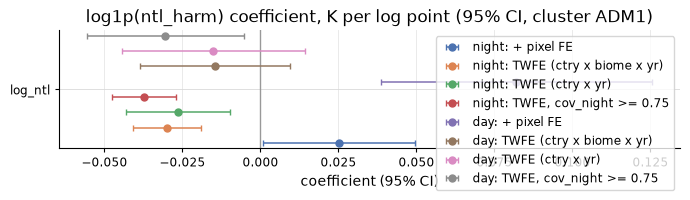

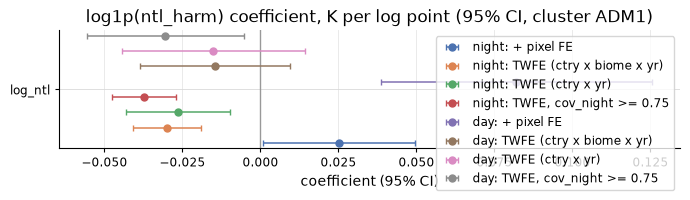

In [3]:
coefplot([b1[(o, l)] for o in ("night", "day") for l in list(ladder)[1:]],
         [f"{o}: {l}" for o in ("night", "day") for l in list(ladder)[1:]],
         XLOG, "log1p(ntl_harm) coefficient, K per log point (95% CI, cluster ADM1)")

**Result.** Night LST: TWFE **−0.030 (0.006)** under country × biome × year, −0.027 (0.009) under
country × year, −0.037 (0.005) on well-observed pixel-years. Day LST: −0.015 (0.012), not
significant. ◇ The sign does not depend on the FE set. As before, pixel FE alone give +0.025
(0.012): the sign turns negative only once cells are compared within their country-biome-year.

## B2. Functional form

`ntl_harm` is zero in 66 % of pixel-years and in (0, 7) in 23 %, a share that moves with the
sensor (P6). `log1p` then mixes two margins, lighting up and brightening, its units matter
(Chen and Roth 2024), and a single slope can average a cooling dim range with a warming bright
range (urban heat islands). Three views:

- **B2a. Dose-response bins:** indicators for DN (0, 7), [7, 20), [20, 30), [30, 50) and ≥ 50
  (reference DN 0), §2 FE, night and day. No functional form imposed.
- **B2b. Margins:** the lit indicator at DN 20 (lighting up) and `log(DN/20)` above it
  (brightening among lit cells), in one regression, night and day.
- **B2c. Transforms:** `log(DN + 0.1)`, `log1p`, `log(DN + 10)`, `asinh` and linear DN, night.

**The functional-form figure** puts the bin estimates (at each bin's mean DN) on the curves each
transform implies, β_f · (f(DN) − f(0)). Where the curves miss the bins, the transform imposes a
shape the data do not have.

In [4]:
BINS = list(NTL_BINS)
LIT_BINS = BINS[1:]
b2a = {"night": fit(f"{Y} ~ {' + '.join(BINS)} | {FE}"),
       "day": fit(f"{Y_DAY} ~ {' + '.join(BINS)} | {FE}", subset=DAY)}
b2b = {"night": fit(f"{Y} ~ lit_hi + log_ntl_above | {FE}"),
       "day": fit(f"{Y_DAY} ~ lit_hi + log_ntl_above | {FE}", subset=DAY)}
TRANS = {  # label: (column, f)
    "log(DN+0.1)": ("log_ntl_c01", lambda d: np.log(d + 0.1)),
    "log1p (baseline)": (XLOG, np.log1p),
    "log(DN+10)": ("log_ntl_c10", lambda d: np.log(d + 10)),
    "asinh": ("asinh_ntl", np.arcsinh),
    "linear DN": ("ntl_harm", lambda d: d),
}
b2c = {k: (m_twfe if col == XLOG else fit(f"{Y} ~ {col} | {FE}")) for k, (col, _) in TRANS.items()}

dn = sql(f"SELECT {', '.join(f'avg(CASE WHEN {c} THEN ntl_harm END) AS {b}' for b, c in NTL_BINS.items())} "
         f"FROM {P} WHERE {BASE}").iloc[0]
sw = sql(f"SELECT {', '.join(f'sum(sw_{b}) AS {b}' for b in BINS)} FROM "
         f"(SELECT {', '.join(f'max({b}) - min({b}) AS sw_{b}' for b in BINS)} FROM {P} WHERE {BASE} GROUP BY pixel_id)").iloc[0]
bins_tab = pd.concat({o: terms(b2a[o], BINS) for o in ("night", "day")}, axis=1)
bins_tab.insert(0, "mean DN", dn.round(1).values)
bins_tab.insert(1, "pixels switching", sw.astype(int).values)
bins_tab.round(4)

mean DN pixels switching   night                                  \
                                       est      se       p      lo      hi   
term                                                                         
bin_lt7       1.8           614371 -0.0159  0.0046  0.0006 -0.0250 -0.0068   
bin_7_20     11.9           255940 -0.0523  0.0092  0.0000 -0.0704 -0.0342   
bin_20_30    24.3            72440 -0.0792  0.0145  0.0000 -0.1076 -0.0509   
bin_30_50    38.4            46348 -0.0797  0.0202  0.0001 -0.1192 -0.0401   
bin_ge50     70.5            18243 -0.0509  0.0314  0.1053 -0.1125  0.0107   

              day                                  
              est      se       p      lo      hi  
term                                               
bin_lt7    0.0483  0.0120  0.0001  0.0247  0.0719  
bin_7_20  -0.0183  0.0215  0.3940 -0.0604  0.0238  
bin_20_30 -0.0389  0.0299  0.1930 -0.0974  0.0197  
bin_30_50 -0.0264  0.0394  0.5032 -0.1036  0.0509  
bin_ge50   0.0388  0.0569  0.4945 -0.0726  0.1503

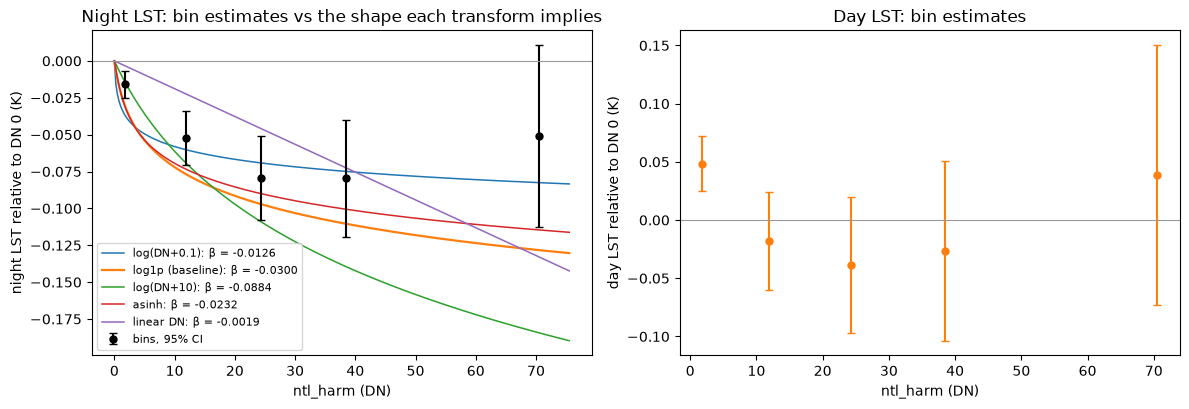

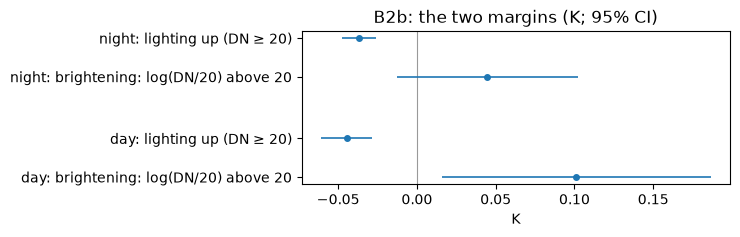

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
d = np.linspace(0, float(dn.max()) + 5, 300)
ax = axes[0]
for k, (col, f) in TRANS.items():
    b = row(b2c[k], col)["est"]
    ax.plot(d, b * (f(d) - f(0)), lw=1.6 if "baseline" in k else 1.1, label=f"{k}: β = {b:+.4f}")
bt = terms(b2a["night"], BINS)
ax.errorbar(dn[BINS].values, bt.est, yerr=[bt.est - bt.lo, bt.hi - bt.est], fmt="o", color="k",
            ms=5, capsize=3, label="bins, 95% CI")
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="ntl_harm (DN)", ylabel="night LST relative to DN 0 (K)",
       title="Night LST: bin estimates vs the shape each transform implies")
ax.legend(fontsize=8)
ax = axes[1]
bd = terms(b2a["day"], BINS)
ax.errorbar(dn[BINS].values, bd.est, yerr=[bd.est - bd.lo, bd.hi - bd.est], fmt="o", color="C1", ms=5, capsize=3)
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="ntl_harm (DN)", ylabel="day LST relative to DN 0 (K)", title="Day LST: bin estimates")
fig.tight_layout()
plt.show()

mg = pd.concat({o: terms(b2b[o], ["lit_hi", "log_ntl_above"]) for o in ("night", "day")}).reset_index()
mg["label"] = mg.term.map({"lit_hi": "lighting up (DN ≥ 20)", "log_ntl_above": "brightening: log(DN/20) above 20"})
mg["group"] = mg.level_0
forest(mg[["group", "label", "est", "lo", "hi"]], "B2b: the two margins (K; 95% CI)", xlabel="K")

In [6]:
for k, (col, _) in TRANS.items():
    if col != XLOG:
        keep("B2c", k, b2c[k], col)
bn = terms(b2a["night"], BINS)
sig = bn.loc[LIT_BINS][bn.loc[LIT_BINS].p < 0.05]
mgn = terms(b2b["night"], ["lit_hi", "log_ntl_above"])
thin = [b for b in BINS if sw[b] < 5000]
rule("B2a", "lit bins (DN >= 7) include a significantly negative and a significantly positive coefficient",
     (sig.est < 0).any() and (sig.est > 0).any(), "the log slope averages opposite effects; report the bins")
rule("B2b", "the two margins have opposite signs, both p < 0.05",
     (mgn.p < 0.05).all() and np.sign(mgn.est).nunique() == 2, "the log slope averages opposite effects; report the margins")
rule("B2a", "the DN (0, 7) bin is the only significant bin",
     bn.loc["bin_lt7", "p"] < 0.05 and (bn.loc[LIT_BINS].p >= 0.05).all(), "the association lives in the dim range; read B4c")
e01, e10 = row(b2c["log(DN+0.1)"], "log_ntl_c01")["est"], row(b2c["log(DN+10)"], "log_ntl_c10")["est"]
rule("B2c", "log(DN+0.1) and log(DN+10) give opposite signs", np.sign(e01) != np.sign(e10),
     "log1p is driven by the zero margin; report the bins")
print(f"P6 rule: bins with < 5,000 switching pixels (reported, not read): {thin or 'none'}")

B2a rule: lit bins (DN >= 7) include a significantly negative and a significantly positive coefficient -> does not fire
B2b rule: the two margins have opposite signs, both p < 0.05 -> does not fire
B2a rule: the DN (0, 7) bin is the only significant bin -> does not fire
B2c rule: log(DN+0.1) and log(DN+10) give opposite signs -> does not fire
P6 rule: bins with < 5,000 switching pixels (reported, not read): none


**Result.** Night bins, relative to DN 0: **−0.016** (0.005) at DN (0, 7), **−0.052** (0.009) at
[7, 20), **−0.079** (0.015) at [20, 30), **−0.080** (0.020) at [30, 50), −0.051 (0.031, p = 0.11) at
≥ 50. The dose-response is negative throughout and flattens above DN 20. In the figure,
`log1p` fits the lower bins but overstates the cooling above DN 20. `log(DN + 0.1)` flattens
most and comes closest to the upper bins; linear DN gets the shape wrong. Every transform is
negative with |t| ≥ 2.3.

The margins (read from the figure; the cell prints no table): at night, lighting up (DN ≥ 20)
is about −0.036 K and significant, while brightening above DN 20 is about +0.045 K with a CI
that includes 0. By day, lighting up is about −0.045 K and brightening about +0.10 K, both
significant. That is the urban-heat-island sign for brightening, but only in daytime LST. The
day dim bin is positive, +0.048 (0.012).

◇ None of the four B2 rules fires. The night association is one of **lighting up, not
brightening**: cells that cross from dark to moderately lit cool; more light beyond DN 20 adds no
further cooling.

## B3. Tighter comparisons (confounding)

Compare cells that are more alike, so fewer outside factors (weather, prices, policy, land use)
can differ between them. Night LST, `log1p(ntl_harm)`, ADM1 clusters throughout.

- **B3a.** pixel + ADM1 × year FE; **B3b.** pixel + ADM2 × year FE.
- **B3c.** §2 FE + baseline land cover × year FE (ESA CCI dominant class of the cell in 2002).
- **B3d.** cell × period FE (2002–07, 2008–12, 2013–17, 2018–22) + country × biome × year: each
  cell gets its own level in each period, a step-wise stand-in for cell trends that also absorbs
  each cell's shift at the 2013 sensor splice.
- **B3e.** neighbour differences: (Y − Y_ring1) on (X − X_ring1) with the §2 FE. This also
  removes spillovers, so a smaller estimate is expected even if the association is real; only
  sign and |t| are read.

In [7]:
b3 = {
    "B3a ADM1 x year":            (fit(f"{Y} ~ {XLOG} | pixel_id + GID_1^year"), XLOG),
    "B3b ADM2 x year":            (fit(f"{Y} ~ {XLOG} | pixel_id + GID_2^year"), XLOG),
    "B3c + land cover x year":    (fit(f"{Y} ~ {XLOG} | {FE} + lc_base^year", subset="lc_base IS NOT NULL"), XLOG),
    "B3d cell x period":          (fit(f"{Y} ~ {XLOG} | pixel_id^period + GID_0^biome_id^year"), XLOG),
    "B3e neighbour differences":  (fit(f"d_lst_night ~ d_log_ntl | {FE}",
                                       subset="d_lst_night IS NOT NULL AND d_log_ntl IS NOT NULL"), "d_log_ntl"),
}
r3 = {k: keep("B3", k[4:], m, t) for k, (m, t) in b3.items()}
rule("B3", "sign flips or |t| < 2 under ADM2 x year or neighbour differences",
     weak(r3["B3b ADM2 x year"]) or weak(r3["B3e neighbour differences"]), "the association does not survive tighter comparisons")
stable = all(r["est"] < 0 and abs(r["est"] / r["se"]) >= 2 and -0.045 <= r["est"] <= -0.015 for r in r3.values())
print(f"B3 stability: every B3 estimate negative, |t| >= 2 and within [-0.045, -0.015]: {stable}")
pd.DataFrame(r3).T[["est", "se", "p", "lo", "hi"]].astype(float).round(4)

Merged FE component 'pixel_id' has estimated MAX(ABS)=1,688,914,284,774,393 ≥ 1,000,000,000. Numeric merge expression may overflow BIGINT for merged FE 'pixel_id_period'. Falling back to VARCHAR merge.


B3 rule: sign flips or |t| < 2 under ADM2 x year or neighbour differences -> FIRES: the association does not survive tighter comparisons
B3 stability: every B3 estimate negative, |t| >= 2 and within [-0.045, -0.015]: False


,est,se,p,lo,hi
B3a ADM1 x year,-0.0201,0.0045,0.0000,-0.0289,-0.0113
B3b ADM2 x year,-0.0102,0.0025,0.0001,-0.0152,-0.0052
B3c + land cover x year,-0.0265,0.0053,0.0000,-0.0369,-0.0161
B3d cell x period,-0.0471,0.0066,0.0000,-0.0599,-0.0342
B3e neighbour differences,-0.0001,0.0009,0.9301,-0.0019,0.0017


**Result.** The coefficient shrinks as the comparison gets more local: country × biome × year
−0.030 → ADM1 × year **−0.020** (0.005) → ADM2 × year **−0.010** (0.003) → neighbour differences
**−0.0001 (0.0009)**. Baseline land cover × year leaves it at −0.027 (0.005). Cell × period FE
raise it to −0.047 (0.007), so it is not a cell-specific trend or a level shift at the 2013 splice.

◇ **The B3 rule fires:** under neighbour differences |t| = 0.09. ADM2 × year passes on its own
(t = −4.0), but the stability band [−0.045, −0.015] fails at both ends.

The neighbour-difference zero is precise, not merely insignificant. Its SE is a sixth of the
baseline's. Even an effect with a spillover of 0.85 into neighbours (the instrument's ring-1
profile, P4) would leave about −0.005 here, t ≈ 5. A zero means night LST falls as much in the
neighbours of a brightening cell as in the cell itself. **The association lives at a regional
scale (tens of km), not at the cell scale.** Two readings fit this, and the current data cannot
separate them:
- regional confounding, e.g. weather or economic shocks that move a region's lights and LST
  together;
- a mechanism that acts regionally, of which aerosols are the obvious one (P5: ACAG PM2.5 is
  almost entirely regional at 10 km).

## B4. Satellite artefacts

Random noise only attenuates β; what matters are errors that move with temperature.

- **B4a.** Snow-prone cells dropped: |lat| ≥ 50°, or the boreal forest/taiga or tundra biome.
  Snow is cold and brightens lights. The flag is crude (plan §4, known problems): a change in β
  can come from sample composition as much as from snow.
- **B4b.** Sensor eras separately: DMSP 2002–12 and VIIRS 2014–22 (the 2013 overlap dropped), each
  with its own FE. Only a sign difference counts against the association; the eras differ in
  length and noise.
- **B4c.** Dim lights set to zero: treatment `log1p(DN · 1[DN ≥ 7])`. The dim range is where the
  sensor splice moves the lit share (P2, P6).

In [8]:
b4 = {
    "B4a snow-prone dropped":  (fit(f"{Y} ~ {XLOG} | {FE}", subset="snow_prone = 0"), XLOG),
    "B4b DMSP 2002-12":        (fit(f"{Y} ~ {XLOG} | {FE}", subset="year <= 2012"), XLOG),
    "B4b VIIRS 2014-22":       (fit(f"{Y} ~ {XLOG} | {FE}", subset="year >= 2014"), XLOG),
    "B4c dim lights zeroed":   (fit(f"{Y} ~ log_ntl_d7 | {FE}"), "log_ntl_d7"),
}
r4 = {k: keep("B4", k[4:], m, t) for k, (m, t) in b4.items()}
rule("B4a", "beta >= 0 or |t| < 2 with snow-prone cells dropped", weak(r4["B4a snow-prone dropped"]),
     "snow is a candidate explanation")
dm, vi = r4["B4b DMSP 2002-12"], r4["B4b VIIRS 2014-22"]
rule("B4b", "the eras differ in sign (both p < 0.05) or one era is positive",
     (dm["p"] < 0.05 and vi["p"] < 0.05 and np.sign(dm["est"]) != np.sign(vi["est"])) or dm["est"] > 0 or vi["est"] > 0,
     "the association is sensor-specific")
rule("B4c", "beta >= 0 or |t| < 2 with dim lights set to zero", weak(r4["B4c dim lights zeroed"]),
     "the association is carried by dim-range lights")
pd.DataFrame(r4).T[["est", "se", "p", "lo", "hi"]].astype(float).round(4)

B4a rule: beta >= 0 or |t| < 2 with snow-prone cells dropped -> does not fire
B4b rule: the eras differ in sign (both p < 0.05) or one era is positive -> does not fire
B4c rule: beta >= 0 or |t| < 2 with dim lights set to zero -> does not fire


,est,se,p,lo,hi
B4a snow-prone dropped,-0.0313,0.0057,0.0,-0.0424,-0.0201
B4b DMSP 2002-12,-0.0545,0.0134,0.0,-0.0807,-0.0282
B4b VIIRS 2014-22,-0.0496,0.0085,0.0,-0.0663,-0.0328
B4c dim lights zeroed,-0.0169,0.0032,0.0,-0.0231,-0.0107


**Result.** No B4 rule fires. Snow-prone cells dropped: −0.031 (0.006). DMSP 2002–12: −0.055
(0.013); VIIRS 2014–22: −0.050 (0.009). Both eras are more negative than the pooled estimate, so
the splice attenuates rather than creates it. Dim lights set to zero (required with B1, P6):
**−0.017 (0.003)**, t = −5.3, about half the baseline. The dim range carries part of the
association but does not produce it.

## B5. Reverse causality: heat slows growth

- **B5a. Sign by baseline climate.** Growth responds to temperature in a hump shape, with an
  optimum near 13 °C (Burke, Hsiang and Miguel 2015). Reverse causality predicts a negative
  coefficient in hot cells and a zero or positive one in cold cells; snow (B4a) predicts a
  negative one in cold cells. Lights × band, baseline GLASS air temperature 2002–04
  (< 5, 5–13, 13–22, ≥ 22 °C), night and day. The band itself is absorbed by the pixel FE.
- **B5b. Timing.** (i) the lead placebo LST_t on X_t and X_{t+2}; (ii) X_t on LST_{t−1} and
  X_{t−1}, night and day LST; (iii) LST_t on X_{t−1} and LST_{t−1}.
- **B5c. Breakdown feedback θ\*.** Under pure reverse causality (β = 0, lights respond to LST
  with θ), the reverse regression of lights on LST recovers θ exactly. θ\* is that coefficient;
  LST noise cannot feed back into growth, so the feedback needed is at least θ\*. Benchmark,
  fixed before the run: |θ| ≈ 0.05 log points per K (plan §4).

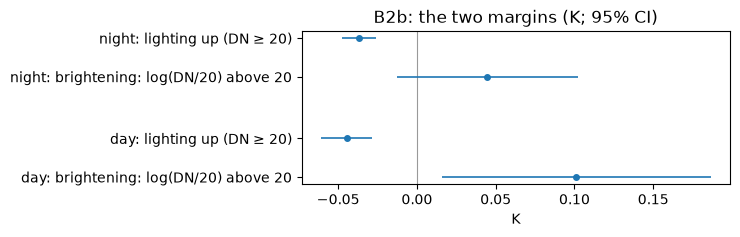

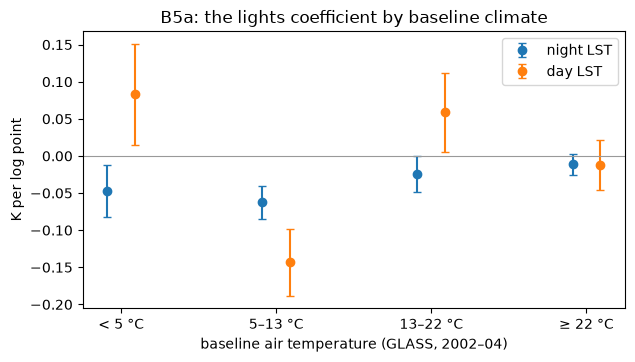

B5a rule: hot band significantly negative and cold band >= 0 (night) -> does not fire
B5a rule: cold band significantly negative (night) -> FIRES: points away from reverse causality (snow or another cold-climate mechanism)


night                                     day                  \
             est      se       p      lo      hi     est      se       p   
tb_lt5   -0.0472  0.0181  0.0092 -0.0827 -0.0117  0.0829  0.0347  0.0169   
tb_5_13  -0.0624  0.0114  0.0000 -0.0848 -0.0401 -0.1435  0.0230  0.0000   
tb_13_22 -0.0245  0.0124  0.0485 -0.0487 -0.0002  0.0586  0.0272  0.0314   
tb_ge22  -0.0115  0.0075  0.1274 -0.0262  0.0033 -0.0125  0.0171  0.4641   

                          
              lo      hi  
tb_lt5    0.0149  0.1510  
tb_5_13  -0.1885 -0.0984  
tb_13_22  0.0052  0.1119  
tb_ge22  -0.0459  0.0209

In [9]:
XB = [f"x_{b}" for b in T_BANDS]
TB = "t_band IS NOT NULL"
b5a = {"night": fit(f"{Y} ~ {' + '.join(XB)} | {FE}", subset=TB),
       "day": fit(f"{Y_DAY} ~ {' + '.join(XB)} | {FE}", subset=f"{TB} AND {DAY}")}
band_tab = pd.concat({o: terms(b5a[o], XB) for o in ("night", "day")}, axis=1)
band_tab.index = list(T_BANDS)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(T_BANDS))
for j, (o, col) in enumerate([("night", "C0"), ("day", "C1")]):
    t = band_tab[o]
    ax.errorbar(x + (j - 0.5) * 0.18, t.est, yerr=[t.est - t.lo, t.hi - t.est], fmt="o", color=col,
                capsize=3, label=f"{o} LST")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xticks(x, ["< 5 °C", "5–13 °C", "13–22 °C", "≥ 22 °C"])
ax.set(xlabel="baseline air temperature (GLASS, 2002–04)", ylabel="K per log point",
       title="B5a: the lights coefficient by baseline climate")
ax.legend()
plt.show()

hot, cold = band_tab.loc["tb_ge22", "night"], band_tab.loc["tb_lt5", "night"]
rule("B5a", "hot band significantly negative and cold band >= 0 (night)",
     hot["est"] < 0 and hot["p"] < 0.05 and cold["est"] >= 0, "the pattern matches reverse causality")
rule("B5a", "cold band significantly negative (night)", cold["est"] < 0 and cold["p"] < 0.05,
     "points away from reverse causality (snow or another cold-climate mechanism)")
band_tab.round(4)

In [10]:
LAGS = "lst_night_lag1 IS NOT NULL AND log_ntl_lag1 IS NOT NULL"
b5b = {
    "(i) LST_t ~ X_t + X_t+2":            (fit(f"{Y} ~ {XLOG} + log_ntl_lead2 | {FE}", subset="log_ntl_lead2 IS NOT NULL"),
                                           [XLOG, "log_ntl_lead2"]),
    "(ii) X_t ~ night LST_t-1 + X_t-1":   (fit(f"{XLOG} ~ lst_night_lag1 + log_ntl_lag1 | {FE}", subset=LAGS),
                                           ["lst_night_lag1", "log_ntl_lag1"]),
    "(ii) X_t ~ day LST_t-1 + X_t-1":     (fit(f"{XLOG} ~ lst_day_lag1 + log_ntl_lag1 | {FE}",
                                               subset="lst_day_lag1 IS NOT NULL AND log_ntl_lag1 IS NOT NULL"),
                                           ["lst_day_lag1", "log_ntl_lag1"]),
    "(iii) LST_t ~ X_t-1 + LST_t-1":      (fit(f"{Y} ~ log_ntl_lag1 + lst_night_lag1 | {FE}", subset=LAGS),
                                           ["log_ntl_lag1", "lst_night_lag1"]),
}
lead = row(b5b["(i) LST_t ~ X_t + X_t+2"][0], "log_ntl_lead2")
fb = row(b5b["(ii) X_t ~ night LST_t-1 + X_t-1"][0], "lst_night_lag1")
fb_day = row(b5b["(ii) X_t ~ day LST_t-1 + X_t-1"][0], "lst_day_lag1")
rule("B5b", "lead of lights significant (p < 0.05) with the sign of B1",
     lead["p"] < 0.05 and np.sign(lead["est"]) == np.sign(B1_EST["est"]), "a common driver or reverse causality is present")
rule("B5b", "lagged night or day LST lowers lights (p < 0.05)",
     any(r["est"] < 0 and r["p"] < 0.05 for r in (fb, fb_day)), "a heat -> lights feedback exists")
pd.concat({k: terms(m, t) for k, (m, t) in b5b.items()}).round(4)

B5b rule: lead of lights significant (p < 0.05) with the sign of B1 -> does not fire
B5b rule: lagged night or day LST lowers lights (p < 0.05) -> FIRES: a heat -> lights feedback exists


est      se       p  \
                                 term                                     
(i) LST_t ~ X_t + X_t+2          log_ntl        -0.0326  0.0056  0.0000   
                                 log_ntl_lead2   0.0104  0.0064  0.1045   
(ii) X_t ~ night LST_t-1 + X_t-1 lst_night_lag1  0.0002  0.0006  0.7911   
                                 log_ntl_lag1    0.4420  0.0113  0.0000   
(ii) X_t ~ day LST_t-1 + X_t-1   lst_day_lag1   -0.0012  0.0005  0.0148   
                                 log_ntl_lag1    0.4421  0.0113  0.0000   
(iii) LST_t ~ X_t-1 + LST_t-1    log_ntl_lag1    0.0034  0.0054  0.5344   
                                 lst_night_lag1  0.0441  0.0056  0.0000   

                                                     lo      hi  
                                 term                            
(i) LST_t ~ X_t + X_t+2          log_ntl        -0.0436 -0.0217  
                                 log_ntl_lead2  -0.0022  0.0230  
(ii) X_t ~ night LST_t-1 + X_t-1 lst_night_lag1 -0.0010  0.0013  
                                 log_ntl_lag1    0.4199  0.4642  
(ii) X_t ~ day LST_t-1 + X_t-1   lst_day_lag1   -0.0022 -0.0002  
                                 log_ntl_lag1    0.4200  0.4643  
(iii) LST_t ~ X_t-1 + LST_t-1    log_ntl_lag1   -0.0072  0.0140  
                                 lst_night_lag1  0.0332  0.0551

In [11]:
b5c = {"night": fit(f"{XLOG} ~ {Y} | {FE}"), "day": fit(f"{XLOG} ~ {Y_DAY} | {FE}", subset=DAY)}
th = {o: row(b5c[o], y) for o, y in (("night", Y), ("day", Y_DAY))}
for o, r in th.items():
    print(f"theta* ({o}): {r['est']:+.4f} ({r['se']:.4f}) log points of lights per K "
          f"= {100 * r['est']:+.2f} % per K")
rule("B5c", "|theta*| (night) <= 0.05 log points per K", abs(th["night"]["est"]) <= 0.05,
     "a feedback of plausible size could produce beta alone")
pd.DataFrame(th).T[["est", "se", "p", "lo", "hi"]].astype(float).round(4)

theta* (night): -0.0043 (0.0008) log points of lights per K = -0.43 % per K
theta* (day): -0.0008 (0.0006) log points of lights per K = -0.08 % per K
B5c rule: |theta*| (night) <= 0.05 log points per K -> FIRES: a feedback of plausible size could produce beta alone


,est,se,p,lo,hi
night,-0.0043,0.0008,0.0000,-0.0059,-0.0027
day,-0.0008,0.0006,0.2308,-0.0020,0.0005


**Result.**

**B5a.** Night, by baseline air temperature: < 5 °C **−0.047** (0.018), 5–13 °C **−0.062** (0.011),
13–22 °C −0.025 (0.012), ≥ 22 °C −0.012 (0.008, p = 0.13). This gradient is the opposite of the
reverse-causality signature. The association is strongest in cool cells, where warming *raises*
growth on the Burke curve, and weakest in hot cells, where heat slows growth.
◇ The "cold band negative" rule fires: this points away from reverse causality. Snow does not
produce the gradient. B4a keeps −0.031 without snow-prone cells, and the 5–13 °C band, only 17 %
snow-prone, has the largest coefficient (P6). The day bands alternate in sign (+0.08, −0.14,
+0.06, −0.01) and are not read.

**B5b.** (i) The lead of lights is +0.010 (0.006), p = 0.10, with the opposite sign to B1: no
anticipation. (ii) Lagged night LST does not move lights: +0.0002 (0.0006), CI [−0.0010,
+0.0013]. Lagged day LST does: −0.0012 (0.0005), p = 0.015. ◇ That rule fires, but the feedback
is small: −0.12 % of lights per K. (iii) Lagged lights do not predict LST (+0.003, p = 0.53),
so the association is contemporaneous.

**B5c.** θ\* (night) = **−0.0043 (0.0008)** log points of lights per K, 12× smaller than the
benchmark of 0.05. ◇ The rule fires: a feedback of plausible size could produce β on its own.
Against that, the one-year-lagged night feedback measured in B5b(ii) has a CI that excludes
−0.0043. The quantitative test therefore cannot rule out reverse causality, while the pattern
(B5a) and the lagged feedback argue against it. Neither test covers a same-year feedback.

## Summary

Every night-LST lights estimate of B1, B3 and B4 against the baseline (dashed). B2c transforms
are in different units and are left to the functional-form figure; B3e is in differences.

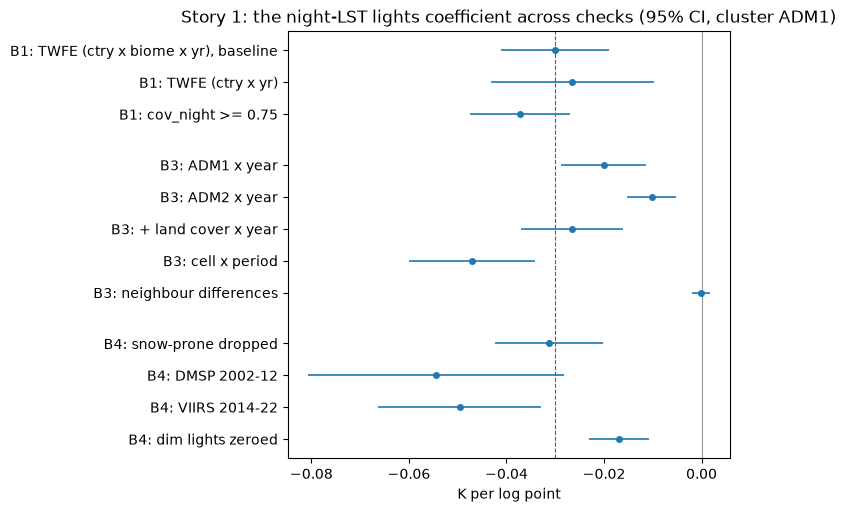

est      se       t       p
group label                                                             
B1    TWFE (ctry x biome x yr), baseline -0.0300  0.0056 -5.3657  0.0000
      TWFE (ctry x yr)                   -0.0265  0.0086 -3.0946  0.0020
      cov_night >= 0.75                  -0.0373  0.0053 -7.0843  0.0000
B2c   log(DN+0.1)                        -0.0126  0.0025 -4.9897  0.0000
      log(DN+10)                         -0.0884  0.0184 -4.8126  0.0000
      asinh                              -0.0232  0.0043 -5.3629  0.0000
      linear DN                          -0.0019  0.0008 -2.3227  0.0202
B3    ADM1 x year                        -0.0201  0.0045 -4.4780  0.0000
      ADM2 x year                        -0.0102  0.0025 -4.0137  0.0001
      + land cover x year                -0.0265  0.0053 -4.9778  0.0000
      cell x period                      -0.0471  0.0066 -7.1848  0.0000
      neighbour differences              -0.0001  0.0009 -0.0877  0.9301
B4    snow-prone dropped                 -0.0313  0.0057 -5.4884  0.0000
      DMSP 2002-12                       -0.0545  0.0134 -4.0649  0.0000
      VIIRS 2014-22                      -0.0496  0.0085 -5.8068  0.0000
      dim lights zeroed                  -0.0169  0.0032 -5.3209  0.0000

,block,rule,fired,reading
0,B1,TWFE sign differs between the two FE sets,False,—
1,B2a,lit bins (DN >= 7) include a significantly neg...,False,—
2,B2b,"the two margins have opposite signs, both p < ...",False,—
3,B2a,"the DN (0, 7) bin is the only significant bin",False,—
4,B2c,log(DN+0.1) and log(DN+10) give opposite signs,False,—
5,B3,sign flips or |t| < 2 under ADM2 x year or nei...,True,the association does not survive tighter compa...
6,B4a,beta >= 0 or |t| < 2 with snow-prone cells dro...,False,—
7,B4b,the eras differ in sign (both p < 0.05) or one...,False,—
8,B4c,beta >= 0 or |t| < 2 with dim lights set to zero,False,—
9,B5a,hot band significantly negative and cold band ...,False,—


In [12]:
est = pd.DataFrame(EST.values())
fig = forest(est[est.group != "B2c"][["group", "label", "est", "lo", "hi"]],
             "Story 1: the night-LST lights coefficient across checks (95% CI, cluster ADM1)",
             ref=B1_EST["est"], xlabel="K per log point")
plt.show()
display(est.set_index(["group", "label"])[["est", "se", "t", "p"]].round(4))
pd.DataFrame(RULES)

**Reading for the decision** (plan §4):

- **Explained away:** any of B2–B5 fires against the association. It is not worth explaining;
  what remains is Story 2's upper bound.
- **Robust:** it survives B3–B4 with a stable sign, and B5 shows no reverse-causality pattern. The
  new-data checks (plan §4, "Later") and Story 3 become worth their cost.
- **Robust but not interpretable:** it survives B3–B4, but θ\* is small or the timing tests fire.
  It then needs Story 2, or the ERA5-Land route, before it can be read as an effect of lights.

**Outcome (2026-09-30): explained away, as a cell-level association.** B3 fires. The coefficient
falls from −0.030 to −0.010 under ADM2 × year and to a precise zero under neighbour
differences.

What holds:
- the sign across FE sets (B1);
- a monotone lighting-up shape (B2);
- no snow, sensor or dim-range artefact (B4);
- a climate gradient that runs against reverse causality (B5a).

But whatever links lights and night LST is shared by neighbouring cells. At the 10 km cell
scale this design identifies from, there is no association left to explain. A regional reading
(regional confounding, or a regional mechanism such as aerosols) stays open, and the current
design cannot separate its two versions.

By the rule, the result of record is **Story 2's upper bound: ±0.3 K per log point**.